<a href="https://www.kaggle.com/code/jatinnabhoya/radiology-report-rag-03-rag-pipeline?scriptVersionId=370381680" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

## install and shared code

In [1]:
!pip install -q -U bitsandbytes faiss-cpu pycocoevalcap
!git clone -q https://github.com/Jatin-nabhoya/Radiology_Report_RAG.git /kaggle/working/repo
import sys; sys.path.append("/kaggle/working/repo/src")
from radrag.config import HF_DATA_REPO, GENERATOR, TOP_K, SEED
from radrag.prompts import build_prompt
print(build_prompt(["Example reference."]))

[INST] <image>
Reference reports from similar chest X-rays:
[1] Example reference.
The references may not match this patient. Use the image as the main evidence.
You are an expert radiologist. Write the FINDINGS section of a radiology report for this frontal chest X-ray. Use short, factual sentences in standard report language. Comment on the heart size, mediastinum, lungs, pleura and bones. State normal findings as normal. Do not explain terms or give advice. [/INST]


## load the split, embeddings and index from Hugging Face

In [2]:
import numpy as np, pandas as pd, faiss, json
from kaggle_secrets import UserSecretsClient
from huggingface_hub import hf_hub_download, HfApi

HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
get = lambda f: hf_hub_download(HF_DATA_REPO, f, repo_type="dataset", token=HF_TOKEN)

df = pd.read_csv(get("iu_xray_clean.csv"))
order = pd.read_csv(get("retrieval/embeddings_order.csv"))
assert (order["uid"].values == df["uid"].values).all()      # same row order as embeddings
embs = np.load(get("retrieval/embeddings_all.npy"))
index = faiss.read_index(get("retrieval/faiss_train.index"))
train_uids = pd.read_csv(get("retrieval/index_ids.csv"))["uid"].values
by_uid = df.set_index("uid")
print(df.shape, embs.shape, index.ntotal)

iu_xray_clean.csv:   0%|          | 0.00/1.17M [00:00<?, ?B/s]

embeddings_order.csv:   0%|          | 0.00/33.0k [00:00<?, ?B/s]

retrieval/embeddings_all.npy: reconstructing file:   0%|          |  0.00B / 1.64MB            

retrieval/embeddings_all.npy: downloading bytes:           |  0.00B            

retrieval/faiss_train.index: reconstructing file:   0%|          |  0.00B / 1.15MB            

retrieval/faiss_train.index: downloading bytes:           |  0.00B            

index_ids.csv:   0%|          | 0.00/20.6k [00:00<?, ?B/s]

(3199, 6) (3199, 128) 2239


## neighbour lists for every X-ray, plus a retrieval check

In [3]:
def norm_text(t): return " ".join(t.lower().split())

sims_all, ids_all = index.search(embs, 20)        # search wide, then filter
neighbours = {}
for row, (uid, sims, ids) in enumerate(zip(df["uid"], sims_all, ids_all)):
    keep, seen = [], set()
    for s, i in zip(sims, ids):
        nuid = int(train_uids[i])
        if nuid == uid: continue                   # never retrieve the query itself
        t = norm_text(by_uid.loc[nuid, "findings"])
        if t in seen: continue                     # drop duplicate report texts
        seen.add(t); keep.append({"uid": nuid, "score": round(float(s), 4)})
        if len(keep) == 5: break
    neighbours[int(uid)] = keep

# Retrieval check on val + test: does the top-3 share the query's normal/abnormal label?
ev = df[df["split"] != "train"]
agree = [np.mean([by_uid.loc[n["uid"], "is_abnormal"] == r.is_abnormal for n in neighbours[r.uid][:3]])
         for r in ev.itertuples()]
ev = ev.assign(agree=agree)
base = df[df["split"] == "train"]["is_abnormal"].mean()
print("Top-3 label agreement:  normal queries %.1f%% (random %.1f%%) | abnormal queries %.1f%% (random %.1f%%)" % (
    100 * ev[ev.is_abnormal == 0].agree.mean(), 100 * (1 - base),
    100 * ev[ev.is_abnormal == 1].agree.mean(), 100 * base))

json.dump(neighbours, open("/kaggle/working/neighbours.json", "w"))
HfApi(token=HF_TOKEN).upload_file(path_or_fileobj="/kaggle/working/neighbours.json",
    path_in_repo="retrieval/neighbours.json", repo_id=HF_DATA_REPO, repo_type="dataset")

No files have been modified since last commit. Skipping to prevent empty commit.


Top-3 label agreement:  normal queries 58.5% (random 36.4%) | abnormal queries 71.9% (random 63.6%)


CommitInfo(commit_url='https://huggingface.co/datasets/jatinnabhoya/Radiology_Report_RAG-data/commit/ebe371be6c9505b9a3220a49e10720cab01a0116', commit_message='Upload retrieval/neighbours.json with huggingface_hub', commit_description='', oid='ebe371be6c9505b9a3220a49e10720cab01a0116', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/jatinnabhoya/Radiology_Report_RAG-data', endpoint='https://huggingface.co', repo_type='dataset', repo_id='jatinnabhoya/Radiology_Report_RAG-data'), pr_revision=None, pr_num=None)

## load LLaVA-Med (4-bit)


In [4]:
import torch
from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
processor = AutoProcessor.from_pretrained(GENERATOR)
model = LlavaForConditionalGeneration.from_pretrained(
    GENERATOR, quantization_config=bnb, device_map={"": 0}, torch_dtype=torch.float16).eval()
print("GPU: %.1f GB" % (torch.cuda.memory_allocated() / 1e9))

processor_config.json:   0%|          | 0.00/168 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/505 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.46k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.41k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.51M [00:00<?, ?B/s]

... (6 outputs left out)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

GPU: 4.3 GB


## the RAG pipeline in one function

In [5]:
from PIL import Image

def generate(image_path, refs=None):
    """refs=None -> condition A (no RAG); refs=list of Findings -> condition C (RAG)."""
    img = Image.open(image_path).convert("RGB")
    inp = processor(images=img, text=build_prompt(refs), return_tensors="pt").to(model.device, torch.float16)
    with torch.inference_mode():
        out = model.generate(**inp, max_new_tokens=150, do_sample=False)
    return processor.decode(out[0][inp["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def rag(uid, k=TOP_K):
    """Retrieve -> augment -> generate for one study."""
    nbs = neighbours[int(uid)][:k]
    refs = [by_uid.loc[n["uid"], "findings"] for n in nbs]
    return generate(by_uid.loc[uid, "image_path"], refs), nbs

## visual demo, 2 normal + 2 abnormal test X-rays (for the slides)

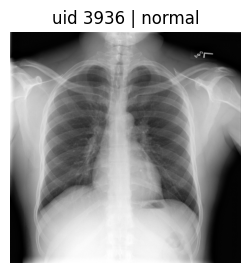

REF 1 (0.972): 2 images. Heart size and pulmonary vascular engorgement appear within limits of normal. Mediastinal contour is
unremarkable. No focal consolidation, pleural effusion, or pneumothorax identified. No convincing acute bony
findings.
REF 2 (0.949): Heart size within normal limits. No focal alveolar consolidation, no definite pleural effusion seen. No
typical findings of pulmonary edema. No pneumothorax.
REF 3 (0.948): Heart size normal. Lungs are clear. are normal. No pneumonia, effusions, edema, pneumothorax, adenopathy,
nodules or masses.

A  no RAG : FINDINGS:  - Heart size is normal. - Mediastinum appears normal. - Lungs show no abnormalities. - Pleura and
bones appear normal.
C  RAG    : FINDINGS: The frontal chest X-ray shows a normal heart size, a normal mediastinum, clear lungs, and no pleural
effusion or pneumothorax. Additionally, there are no typical findings of pulmonary edema. The bones appear
normal.
TRUTH     : Heart size within normal limits. No alveolar cons

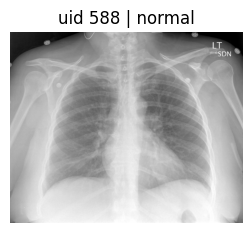

REF 1 (0.986): The cardiomediastinal silhouette is within normal limits for size and contour. The lungs are normally inflated
without evidence of focal airspace disease, pleural effusion, or pneumothorax. Osseous structures are within
normal limits for patient age..
REF 2 (0.986): The heart is normal size. The mediastinum is unremarkable. There is no pleural effusion, pneumothorax, or
focal airspace disease. Mild degenerative changes are present within the spine.
REF 3 (0.986): Lungs are clear without focal consolidation, effusion, or pneumothorax. Normal heart size. Bony thorax and
soft tissues grossly unremarkable.

A  no RAG : FINDINGS:  - Heart size is normal. - Mediastinum appears normal. - Lungs show no abnormalities. - Pleura and
bones appear normal.
C  RAG    : FINDINGS: The heart size appears to be normal. The mediastinum is unremarkable. The lungs are clear without
focal consolidation, effusion, or pneumothorax. The pleura and bones also appear to be normal.
TRUTH     : The h

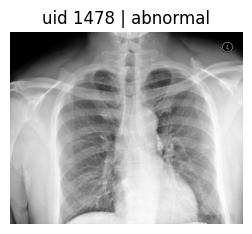

REF 1 (0.965): Lungs are clear. A calcified small granuloma is present in the left lower lobe. Heart size normal. Mediastinum
normal.
REF 2 (0.948): The cardiomediastinal silhouette is normal in size and contour. Aortic atherosclerosis. No focal
consolidation, pneumothorax or large pleural effusion. Negative for acute bone abnormality.
REF 3 (0.944): The cardiomediastinal silhouette is within normal limits for appearance. Calcified right hilar lymph are
demonstrated. Atherosclerotic calcifications of the aortic . No focal areas of pulmonary consolidation. No
pneumothorax. No pleural effusion. Mild to moderate degenerative changes of the thoracic spine.

A  no RAG : FINDINGS:  - Heart size is normal. - Mediastinum appears normal. - Lungs show no abnormalities. - Pleura and
bones appear normal.
C  RAG    : FINDINGS: The heart size appears to be normal. The mediastinum is also within normal limits. The lungs show no
focal areas of pulmonary consolidation, pneumothorax, or large pleural ef

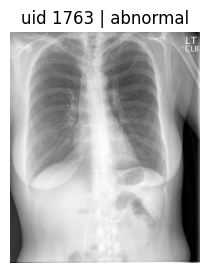

REF 1 (0.962): The heart and cardiomediastinal silhouette are stable in size and contour. There is no focal airspace opacity,
pleural effusion, or pneumothorax. The osseous structures are intact.
REF 2 (0.960): The lungs are clear. There is no focal airspace consolidation. No pleural effusion or pneumothorax. Heart size
and mediastinal contour are within normal limits. There are degenerative changes of the spine.
REF 3 (0.955): The lungs are clear. The cardiomediastinal silhouette is within normal limits. No pleural effusion is
identified.

A  no RAG : FINDINGS:  - Heart size is normal. - Mediastinum appears normal. - Lungs show no abnormalities. - Pleura and
bones appear normal.
C  RAG    : FINDINGS: The heart size and mediastinum appear to be within normal limits. The lungs are clear, with no focal
airspace consolidation or pleural effusion. The osseous structures, including the spine, are intact.
TRUTH     : Heart , mediastinum, , bony structures are unremarkable. Stable increased l

In [6]:
import matplotlib.pyplot as plt, textwrap

test = df[df["split"] == "test"]
demo = pd.concat([test[test.is_abnormal == 0].sample(2, random_state=SEED),
                  test[test.is_abnormal == 1].sample(2, random_state=SEED)])
w = lambda t: "\n".join(textwrap.wrap(t, 110))

for r in demo.itertuples():
    out_c, nbs = rag(r.uid)
    out_a = generate(r.image_path)
    plt.figure(figsize=(3, 3)); plt.imshow(Image.open(r.image_path), cmap="gray"); plt.axis("off")
    plt.title(f"uid {r.uid} | {'abnormal' if r.is_abnormal else 'normal'}"); plt.show()
    for j, n in enumerate(nbs, 1):
        print(f"REF {j} ({n['score']:.3f}):", w(by_uid.loc[n['uid'], 'findings']))
    print("\nA  no RAG :", w(out_a))
    print("C  RAG    :", w(out_c))
    print("TRUTH     :", w(r.findings), "\n" + "=" * 110)

## early scores, A vs C on 100 test X-rays (about 50 minutes)

In [7]:
from tqdm.auto import tqdm
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.rouge.rouge import Rouge

N = 100
sub = test.sample(N, random_state=SEED)
rows = []
for r in tqdm(sub.itertuples(), total=N):
    rows.append(dict(uid=r.uid, image_path=r.image_path, condition="A",
                     generated_findings=generate(r.image_path), reference_findings=r.findings, is_abnormal=r.is_abnormal))
    rows.append(dict(uid=r.uid, image_path=r.image_path, condition="C",
                     generated_findings=rag(r.uid)[0], reference_findings=r.findings, is_abnormal=r.is_abnormal))
preds = pd.DataFrame(rows)
preds.to_csv("/kaggle/working/preds_A_C_n100.csv", index=False)

tok = lambda t: " ".join(t.lower().replace(".", " .").replace(",", " ,").split())
for cond in ["A", "C"]:
    p = preds[preds.condition == cond]
    gts = {i: [tok(t)] for i, t in enumerate(p.reference_findings)}
    res = {i: [tok(t)] for i, t in enumerate(p.generated_findings)}
    b4 = Bleu(4).compute_score(gts, res, verbose=0)[0][3]
    rl = Rouge().compute_score(gts, res)[0]
    print(f"{cond}: BLEU-4 {b4:.3f} | ROUGE-L {rl:.3f}")

HfApi(token=HF_TOKEN).upload_file(path_or_fileobj="/kaggle/working/preds_A_C_n100.csv",
    path_in_repo="predictions/preds_A_C_n100.csv", repo_id=HF_DATA_REPO, repo_type="dataset")

  0%|          | 0/100 [00:00<?, ?it/s]

No files have been modified since last commit. Skipping to prevent empty commit.


A: BLEU-4 0.021 | ROUGE-L 0.235
C: BLEU-4 0.072 | ROUGE-L 0.287


CommitInfo(commit_url='https://huggingface.co/datasets/jatinnabhoya/Radiology_Report_RAG-data/commit/ebe371be6c9505b9a3220a49e10720cab01a0116', commit_message='Upload predictions/preds_A_C_n100.csv with huggingface_hub', commit_description='', oid='ebe371be6c9505b9a3220a49e10720cab01a0116', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/jatinnabhoya/Radiology_Report_RAG-data', endpoint='https://huggingface.co', repo_type='dataset', repo_id='jatinnabhoya/Radiology_Report_RAG-data'), pr_revision=None, pr_num=None)